# Movie semantic search: model comparison

This report completes the evaluation pipeline described in `pipeline/README.md`.
It compares five pretrained multilingual embedding models and a TF-IDF baseline
using the saved cosine-retrieval results from `04_evaluate.py`.

The evaluated movie text contains **title, genres, keywords, and production companies**.
There is one movie-text representation in this experiment. English and Italian
queries describe the same information needs. No reranker is included in these results.

The tables and charts are saved inside this notebook, so it can be read without
rerunning embeddings. To refresh it, run all cells from the repository root or the
`pipeline` directory. It reads the comparison CSV and ground-truth JSON, and exports
the figures to `pipeline/results/figures/`.

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter, MaxNLocator
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

current_dir = Path.cwd()
if (current_dir / "pipeline" / "results" / "comparison_table.csv").is_file():
    pipeline_dir = current_dir / "pipeline"
elif (current_dir / "results" / "comparison_table.csv").is_file():
    pipeline_dir = current_dir
else:
    raise FileNotFoundError("Open the notebook from the repository root or pipeline directory.")

results_dir = pipeline_dir / "results"
figures_dir = results_dir / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "figure.dpi": 110,
    "savefig.dpi": 200,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "svg.fonttype": "none",
})

language_colors = {"EN": "#2563A6", "IT": "#DA7C30"}
model_names = {
    "TF-IDF": "TF-IDF",
    "paraphrase-multilingual-MiniLM-L12-v2": "MiniLM-L12",
    "paraphrase-multilingual-mpnet-base-v2": "Multilingual MPNet",
    "intfloat/multilingual-e5-small": "E5-small",
    "intfloat/multilingual-e5-base": "E5-base",
    "BAAI/bge-m3": "BGE-M3",
}
model_order = list(model_names)


def save_and_show(figure, name):
    figure.savefig(figures_dir / f"{name}.png", bbox_inches="tight", facecolor="white")
    figure.savefig(figures_dir / f"{name}.svg", bbox_inches="tight", facecolor="white")
    display(figure)
    plt.close(figure)

## 1. Saved experiment and inputs

`results/comparison_table.csv` is the source of all model scores below. The notebook
does not use the older detailed evaluation exports and does not load embedding models.
`data/ground_truth.json` supplies query counts and the number of labeled relevant movies.

In [2]:
metric_columns = ["Recall@3 (EN)", "MRR (EN)", "Recall@3 (IT)", "MRR (IT)"]
comparison = pd.read_csv(results_dir / "comparison_table.csv")
if comparison["Model"].duplicated().any() or set(comparison["Model"]) != set(model_order):
    raise ValueError("The comparison must contain one row for each of the six candidates.")
comparison = comparison.set_index("Model").loc[model_order, metric_columns]
if comparison.isna().any().any() or not comparison.ge(0).all().all() or not comparison.le(1).all().all():
    raise ValueError("Evaluation scores must be present and between zero and one.")

with (pipeline_dir / "data" / "ground_truth.json").open(encoding="utf-8") as source:
    ground_truth = json.load(source)
query_context = pd.DataFrame([
    {
        "Query ID": query_id,
        "Query type": labels["query_type"],
        "Relevant movies": len({movie["movie_id"] for movie in labels["relevant_movies"]}),
    }
    for query_id, labels in ground_truth.items()
])
if query_context["Relevant movies"].le(0).any():
    raise ValueError("Every evaluation query needs at least one labeled relevant movie.")

context_rows = [
    ("Candidates", len(comparison)),
    ("Languages", "English and Italian"),
    ("Information needs", len(query_context)),
    ("Query texts across both languages", 2 * len(query_context)),
    ("Metadata queries per language", int(query_context["Query type"].eq("metadata").sum())),
    ("Sequel queries per language", int(query_context["Query type"].eq("sequel").sum())),
]
movie_ids_path = pipeline_dir / "data" / "title_genres_keywords_production_companies" / "movie_ids.npy"
if movie_ids_path.is_file():
    movie_count = len(np.load(movie_ids_path, mmap_mode="r", allow_pickle=False))
    context_rows.insert(0, ("Movies in the saved corpus", f"{movie_count:,}"))
display(pd.DataFrame(context_rows, columns=["Experiment", "Value"]).set_index("Experiment"))

,Value
Experiment,
Movies in the saved corpus,"662,083"
Candidates,6
Languages,English and Italian
Information needs,70
Query texts across both languages,140
Metadata queries per language,62
Sequel queries per language,8


## 2. What the metrics measure

For each query, movies are ranked by descending cosine similarity. Exact score ties
are ordered by ascending movie ID, matching script 04.

$$\mathrm{Recall@3}(q)=\frac{|\mathrm{Top3}(q)\cap\mathrm{Relevant}(q)|}{|\mathrm{Relevant}(q)|}$$

The reported Recall@3 is the mean of these query-level values. Its denominator is
**all labeled relevant movies**, not three.

$$\mathrm{MRR}=\frac{1}{Q}\sum_{q=1}^{Q}\frac{1}{\mathrm{rank\ of\ the\ first\ relevant\ movie}}$$

MRR uses the **full catalog ranking**, rather than stopping at rank three. For example,
a first relevant movie at rank four contributes 0.25 to MRR and zero to Recall@3.
Both metrics range from zero to one, and higher values are better.

In [3]:
display(
    comparison.style
    .format("{:.6f}")
    .highlight_max(axis=0, props="font-weight: bold; background-color: #e7f1fa;")
    .set_caption("Saved evaluation scores. The highest score in each column is highlighted.")
)

,Recall@3 (EN),MRR (EN),Recall@3 (IT),MRR (IT)
Model,,,,
TF-IDF,0.001036,0.099488,0.000913,0.051981
paraphrase-multilingual-MiniLM-L12-v2,0.004764,0.446381,0.004588,0.446451
paraphrase-multilingual-mpnet-base-v2,0.035368,0.467293,0.049936,0.451304
intfloat/multilingual-e5-small,0.034027,0.493598,0.031248,0.347775
intfloat/multilingual-e5-base,0.046274,0.355546,0.034070,0.501150
BAAI/bge-m3,0.003421,0.182430,0.004644,0.214495


## 3. Recall@3 by model and language

This chart shows the fraction of all labeled relevant movies recovered in the top
three. The axis and bar labels express that fraction as a percentage.

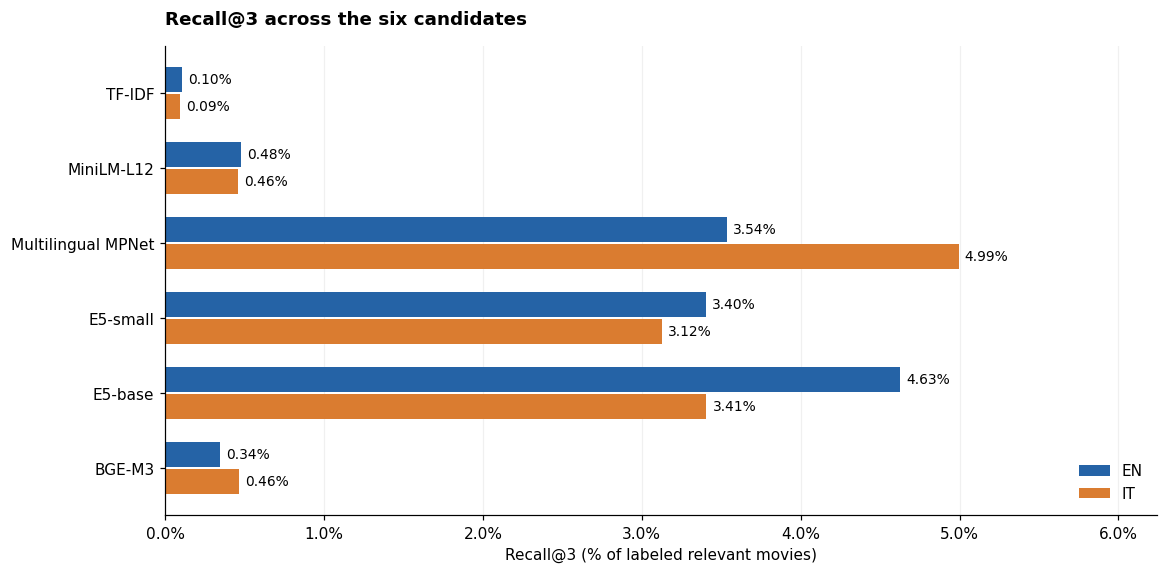

In [4]:
positions = np.arange(len(comparison))
figure, axis = plt.subplots(figsize=(10.5, 5.1), layout="constrained")
for offset, language in [(-0.18, "EN"), (0.18, "IT")]:
    values = comparison[f"Recall@3 ({language})"].to_numpy()
    bars = axis.barh(positions + offset, values, height=0.33,
                     label=language, color=language_colors[language])
    axis.bar_label(bars, labels=[f"{value:.2%}" for value in values], padding=4, fontsize=9)
axis.set_yticks(positions, [model_names[model] for model in comparison.index])
axis.invert_yaxis()
axis.set_xlim(0, comparison[["Recall@3 (EN)", "Recall@3 (IT)"]].to_numpy().max() * 1.25)
axis.xaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=1))
axis.set_xlabel("Recall@3 (% of labeled relevant movies)")
axis.set_title("Recall@3 across the six candidates", loc="left", pad=14)
axis.xaxis.grid(True, alpha=0.18)
axis.set_axisbelow(True)
axis.legend(frameon=False, loc="lower right")
save_and_show(figure, "recall_at_3_by_language")

## 4. MRR by model and language

MRR rewards placing the first relevant movie near the beginning of the ranking.
It answers a different question from Recall@3: a model can find one useful movie
early while recovering only a small fraction of a large relevant set.

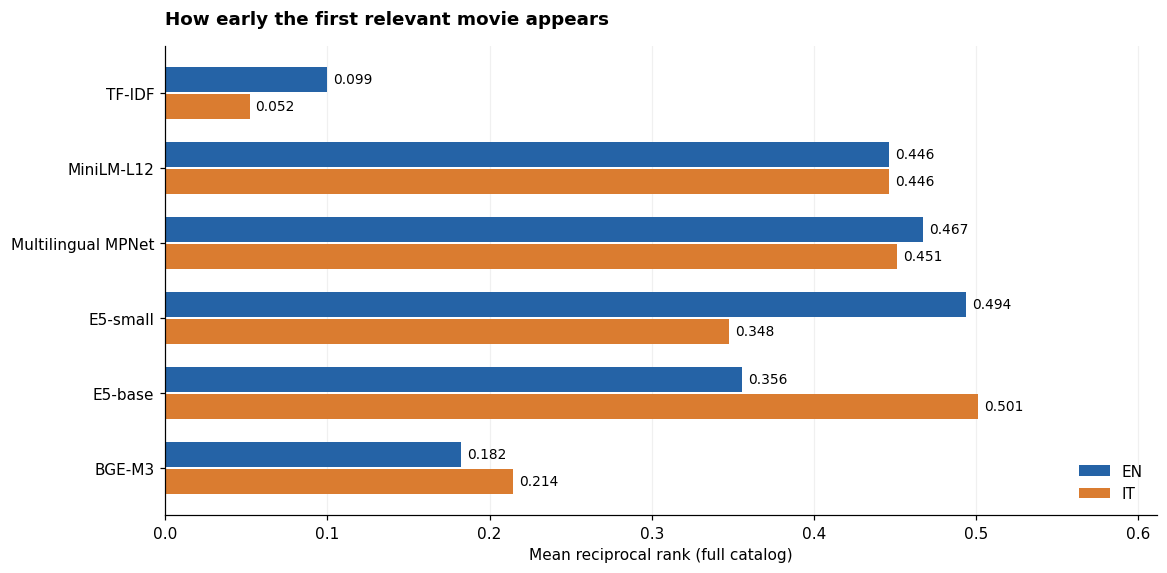

In [5]:
figure, axis = plt.subplots(figsize=(10.5, 5.1), layout="constrained")
for offset, language in [(-0.18, "EN"), (0.18, "IT")]:
    values = comparison[f"MRR ({language})"].to_numpy()
    bars = axis.barh(positions + offset, values, height=0.33,
                     label=language, color=language_colors[language])
    axis.bar_label(bars, labels=[f"{value:.3f}" for value in values], padding=4, fontsize=9)
axis.set_yticks(positions, [model_names[model] for model in comparison.index])
axis.invert_yaxis()
axis.set_xlim(0, comparison[["MRR (EN)", "MRR (IT)"]].to_numpy().max() * 1.22)
axis.set_xlabel("Mean reciprocal rank (full catalog)")
axis.set_title("How early the first relevant movie appears", loc="left", pad=14)
axis.xaxis.grid(True, alpha=0.18)
axis.set_axisbelow(True)
axis.legend(frameon=False, loc="lower right")
save_and_show(figure, "mrr_by_language")

## 5. English versus Italian

The following differences are **Italian minus English**. Positive values favor Italian;
negative values favor English. Recall differences are expressed in percentage points,
while MRR differences use the original zero-to-one score scale.

,Recall@3 gap (percentage points),MRR gap
Model,,
TF-IDF,-0.0123,-0.0475
paraphrase-multilingual-MiniLM-L12-v2,-0.0176,+0.0001
paraphrase-multilingual-mpnet-base-v2,+1.4568,-0.0160
intfloat/multilingual-e5-small,-0.2779,-0.1458
intfloat/multilingual-e5-base,-1.2204,+0.1456
BAAI/bge-m3,+0.1223,+0.0321


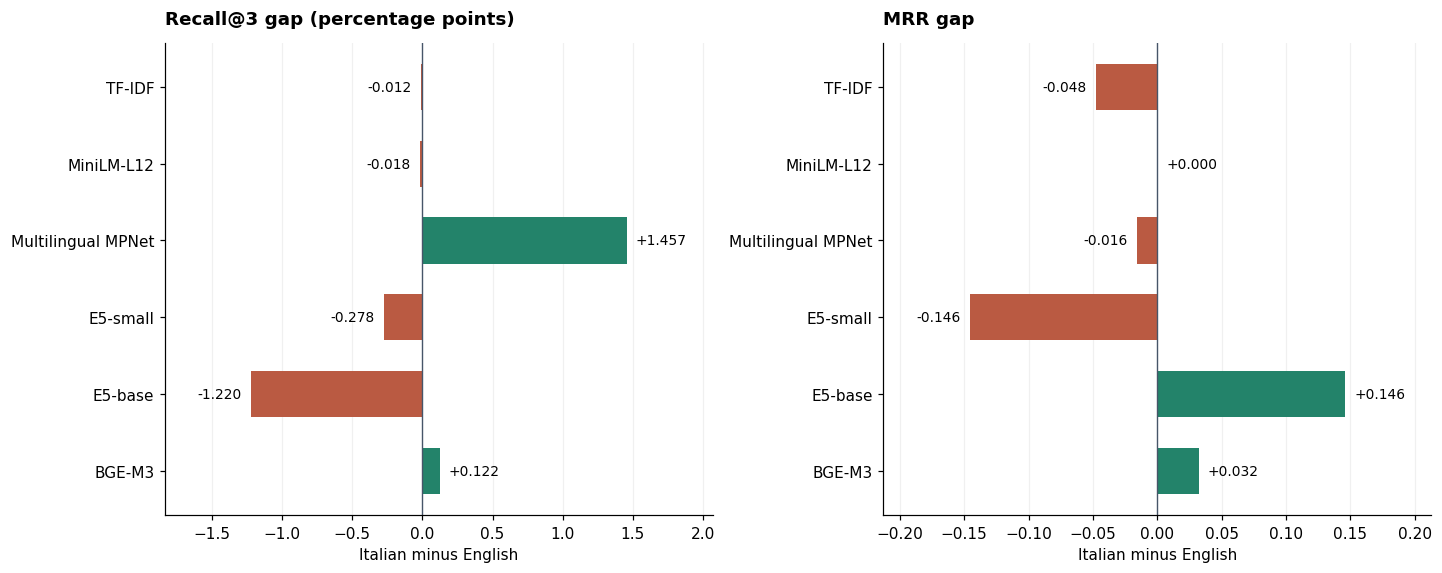

In [6]:
language_gap = pd.DataFrame({
    "Recall@3 gap (percentage points)":
        100 * (comparison["Recall@3 (IT)"] - comparison["Recall@3 (EN)"]),
    "MRR gap": comparison["MRR (IT)"] - comparison["MRR (EN)"],
})
display(language_gap.style.format("{:+.4f}"))

figure, axes = plt.subplots(1, 2, figsize=(13, 5.1), layout="constrained")
for axis, column in zip(axes, language_gap.columns):
    values = language_gap[column].to_numpy()
    colors = ["#23836A" if value >= 0 else "#BA5A42" for value in values]
    axis.barh(positions, values, height=0.6, color=colors)
    axis.set_yticks(positions, [model_names[model] for model in comparison.index])
    axis.invert_yaxis()
    axis.axvline(0, color="#475569", linewidth=0.9)
    span = max(float(np.ptp(values)), float(np.max(np.abs(values))), 0.01)
    axis.set_xlim(min(0, values.min()) - span * 0.23,
                  max(0, values.max()) + span * 0.23)
    for position, value in zip(positions, values):
        axis.text(value + (0.025 * span if value >= 0 else -0.025 * span), position,
                  f"{value:+.3f}", va="center", ha="left" if value >= 0 else "right", fontsize=9)
    axis.set_title(column, loc="left", pad=12)
    axis.set_xlabel("Italian minus English")
    axis.xaxis.grid(True, alpha=0.18)
    axis.set_axisbelow(True)
save_and_show(figure, "italian_minus_english")

## 6. Recall and ranking quality together

Each point represents one model. Points further right recover a larger fraction of
the relevant set; points higher up place the first relevant movie earlier.
Both panels use the same scales so the languages can be compared.

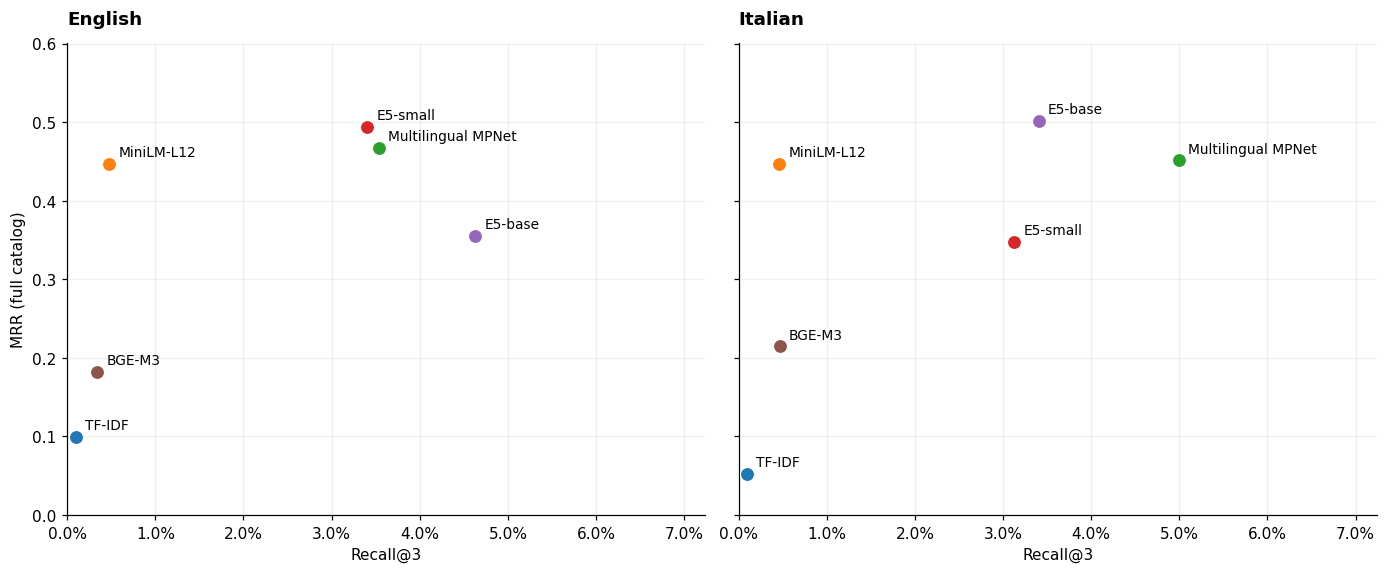

In [7]:
figure, axes = plt.subplots(1, 2, figsize=(12.5, 5.1), layout="constrained",
                            sharex=True, sharey=True)
model_colors = plt.get_cmap("tab10")(np.arange(len(comparison)))
maximum_recall = comparison[["Recall@3 (EN)", "Recall@3 (IT)"]].to_numpy().max()
maximum_mrr = comparison[["MRR (EN)", "MRR (IT)"]].to_numpy().max()
for axis, language in zip(axes, ["EN", "IT"]):
    for color, (model, row) in zip(model_colors, comparison.iterrows()):
        x, y = row[f"Recall@3 ({language})"], row[f"MRR ({language})"]
        axis.scatter(x, y, color=color, s=85, edgecolor="white", linewidth=0.8, zorder=3)
        axis.annotate(model_names[model], (x, y), xytext=(6, 5),
                      textcoords="offset points", fontsize=9)
    axis.set_xlim(0, maximum_recall * 1.45)
    axis.set_ylim(0, maximum_mrr * 1.2)
    axis.xaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=1))
    axis.set_xlabel("Recall@3")
    axis.set_title("English" if language == "EN" else "Italian", loc="left", pad=12)
    axis.grid(alpha=0.18)
axes[0].set_ylabel("MRR (full catalog)")
save_and_show(figure, "recall_vs_mrr")

## 7. Why Recall@3 is small

A query with 100 relevant movies can recover at most 3/100 = 3% of them in three
results. A sequel query with one correct answer can reach 100%. The label counts
therefore matter when interpreting the aggregate Recall@3.

The following graph counts **information needs once**, rather than counting their
English and Italian translations twice. It describes the ground truth, not separate
model performance on metadata and sequels.

,Queries,Minimum,Median,Maximum
Query type,,,,
metadata,62,7,278.5,2900
sequel,8,1,1.0,1


Even with ideal top-three results for every query, the mean Recall@3 for this label set cannot exceed **14.89%**. This ceiling is context; the reported model scores remain the original Recall@3 values.

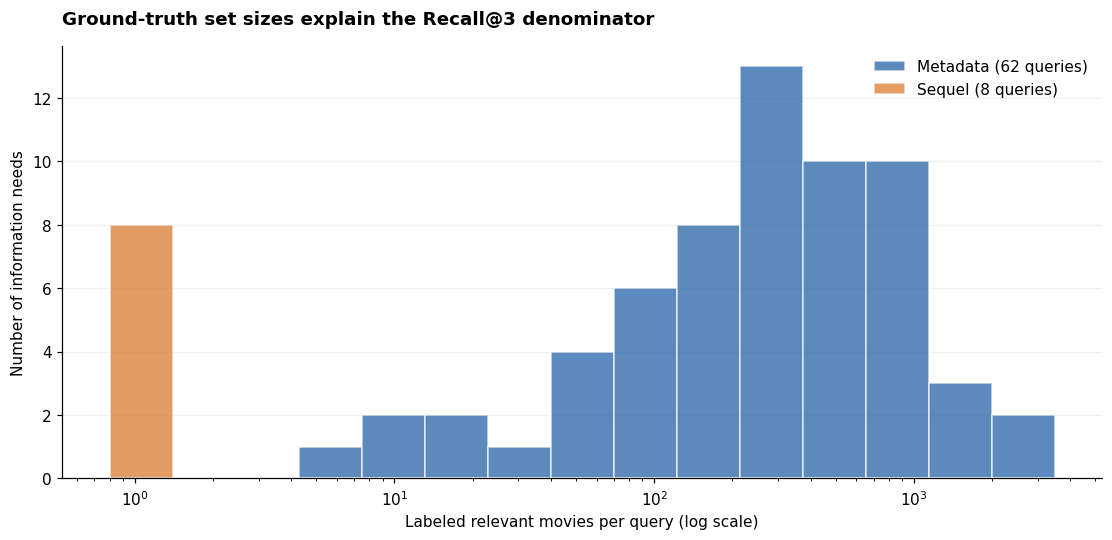

In [8]:
label_summary = query_context.groupby("Query type")["Relevant movies"].agg(
    Queries="size", Minimum="min", Median="median", Maximum="max"
)
display(label_summary)

maximum_per_query = np.minimum(3, query_context["Relevant movies"]) / query_context["Relevant movies"]
maximum_mean_recall = maximum_per_query.mean()
display(Markdown(
    f"Even with ideal top-three results for every query, the mean Recall@3 for "
    f"this label set cannot exceed **{maximum_mean_recall:.2%}**. "
    "This ceiling is context; the reported model scores remain the original Recall@3 values."
))

bins = np.geomspace(0.8, query_context["Relevant movies"].max() * 1.2, 16)
figure, axis = plt.subplots(figsize=(10, 4.8), layout="constrained")
for query_type, color in [("metadata", "#2563A6"), ("sequel", "#DA7C30")]:
    counts = query_context.loc[query_context["Query type"].eq(query_type), "Relevant movies"]
    axis.hist(counts, bins=bins, color=color, alpha=0.75,
              label=f"{query_type.capitalize()} ({len(counts)} queries)", edgecolor="white")
axis.set_xscale("log")
axis.set_xlabel("Labeled relevant movies per query (log scale)")
axis.set_ylabel("Number of information needs")
axis.set_title("Ground-truth set sizes explain the Recall@3 denominator", loc="left", pad=14)
axis.yaxis.set_major_locator(MaxNLocator(integer=True))
axis.yaxis.grid(True, alpha=0.18)
axis.set_axisbelow(True)
axis.legend(frameon=False)
save_and_show(figure, "relevant_movie_counts")

## 8. Model selection from these results

The first table identifies the leader for each language and metric. The second gives
equal weight to English and Italian by averaging their two scores. These bilingual
means are summaries of the same paired information needs, not an independent test set.

In [9]:
leaders = []
for language in ["EN", "IT"]:
    for metric in ["Recall@3", "MRR"]:
        column = f"{metric} ({language})"
        best_model = comparison[column].idxmax()
        leaders.append({"Language": language, "Metric": metric,
                        "Leading model": best_model, "Score": comparison.loc[best_model, column]})
display(pd.DataFrame(leaders).style.format({"Score": "{:.6f}"}).hide(axis="index"))

bilingual_means = pd.DataFrame({
    "Mean Recall@3": comparison[["Recall@3 (EN)", "Recall@3 (IT)"]].mean(axis=1),
    "Mean MRR": comparison[["MRR (EN)", "MRR (IT)"]].mean(axis=1),
}).sort_values("Mean MRR", ascending=False)
display(bilingual_means.style.format("{:.6f}").highlight_max(
    axis=0, props="font-weight: bold; background-color: #e7f1fa;"
))

best_recall = bilingual_means["Mean Recall@3"].idxmax()
best_mrr = bilingual_means["Mean MRR"].idxmax()
if best_recall == best_mrr:
    conclusion = (
        f"**Provisional bilingual choice: `{best_mrr}`.** It has the highest "
        f"mean Recall@3 ({bilingual_means.loc[best_mrr, 'Mean Recall@3']:.6f}) and "
        f"mean MRR ({bilingual_means.loc[best_mrr, 'Mean MRR']:.6f}) on this benchmark."
    )
else:
    conclusion = (
        f"`{best_recall}` leads mean Recall@3, while `{best_mrr}` leads mean MRR. "
        "The preferred model depends on which retrieval objective the application prioritizes."
    )
display(Markdown(conclusion))

Language,Metric,Leading model,Score
EN,Recall@3,intfloat/multilingual-e5-base,0.046274
EN,MRR,intfloat/multilingual-e5-small,0.493598
IT,Recall@3,paraphrase-multilingual-mpnet-base-v2,0.049936
IT,MRR,intfloat/multilingual-e5-base,0.501150


,Mean Recall@3,Mean MRR
Model,,
paraphrase-multilingual-mpnet-base-v2,0.042652,0.459299
paraphrase-multilingual-MiniLM-L12-v2,0.004676,0.446416
intfloat/multilingual-e5-base,0.040172,0.428348
intfloat/multilingual-e5-small,0.032637,0.420687
BAAI/bge-m3,0.004033,0.198462
TF-IDF,0.000975,0.075734


**Provisional bilingual choice: `paraphrase-multilingual-mpnet-base-v2`.** It has the highest mean Recall@3 (0.042652) and mean MRR (0.459299) on this benchmark.

## 9. Interpretation and limits

- Metadata relevance is derived from exact genre, keyword, and production-company rules.
  These are **weak labels**, so the results measure agreement with those rules rather
  than independent human judgments of all semantically relevant movies.
- The eight sequel queries use explicit immediate-sequel answers. The aggregate CSV
  does not establish separate sequel accuracy, and the movie text does not encode an
  explicit sequel relationship.
- These queries support model selection. A separate held-out set would be needed to
  measure performance after the model and settings have been selected.
- One movie-text representation is evaluated. These results do not establish that it
  is better than an alternative containing the overview.
- Runtime, memory, and reranker quality were not measured in the saved comparison.
  The report therefore makes no speed, resource-use, or reranking claims.

The PNG and SVG exports in `results/figures/` can be used in the presentation.
The notebook can be refreshed with **Run All** after updating `comparison_table.csv`.